In [4]:
import sys, platform, os, importlib
print(f"python: {sys.executable}\nversion: {sys.version.split()[0]}\nplatform: {platform.platform()}\ncwd: {os.getcwd()}\nin_venv: {sys.prefix != sys.base_prefix}\nvenv: {sys.prefix}")
print("\n".join(f"{n}: " + (getattr(importlib.import_module(n), '__version__', 'OK') if importlib.util.find_spec(n) else "MISSING") for n in ["numpy","pandas","matplotlib","PIL","yaml","ipykernel"]))

python: c:\Users\ycode\Desktop\2nd_YouCode\briefs\MRI_class_DL\.venv\Scripts\python.exe
version: 3.12.10
platform: Windows-11-10.0.26200-SP0
cwd: c:\Users\ycode\Desktop\2nd_YouCode\briefs\MRI_class_DL\notebooks
in_venv: True
venv: c:\Users\ycode\Desktop\2nd_YouCode\briefs\MRI_class_DL\.venv
numpy: 2.5.4
pandas: 3.0.6
matplotlib: 3.11.2
PIL: 13.0.0
yaml: 6.0.3
ipykernel: 7.4.0


# MRI Brain Tumor — Data Exploration

**Dataset:** `data_set/` — 4 classes (Glioma, Meningioma, No Tumor, Pituitary), Train/Val splits.
**Goal of this notebook:** Understand the data, verify annotations, and resolve the open question of whether "No Tumor" label files contain real boxes. No modeling here.

## 1.2 — Dataset path sanity check

Verify the folder tree exists exactly as expected: `data_set/{Train,Val}/{Glioma,Meningioma,No Tumor,Pituitary}/{images,labels}`.
No file contents are read here — only structure.

In [5]:
from pathlib import Path

DATASET_ROOT = Path(r"C:\Users\ycode\Desktop\2nd_YouCode\briefs\MRI_class_DL\data_set")
SPLITS = ["Train", "Val"]
CLASSES = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]

print(f"root exists: {DATASET_ROOT.exists()} -> {DATASET_ROOT}\n")
for s in SPLITS:
    for c in CLASSES:
        base = DATASET_ROOT / s / c
        print(f"{s:5s} | {c:12s} | folder: {str(base.exists()):5} | images/: {str((base/'images').exists()):5} | labels/: {str((base/'labels').exists()):5}")

root exists: True -> C:\Users\ycode\Desktop\2nd_YouCode\briefs\MRI_class_DL\data_set

Train | Glioma       | folder: True  | images/: True  | labels/: True 
Train | Meningioma   | folder: True  | images/: True  | labels/: True 
Train | No Tumor     | folder: True  | images/: True  | labels/: True 
Train | Pituitary    | folder: True  | images/: True  | labels/: True 
Val   | Glioma       | folder: True  | images/: True  | labels/: True 
Val   | Meningioma   | folder: True  | images/: True  | labels/: True 
Val   | No Tumor     | folder: True  | images/: True  | labels/: True 
Val   | Pituitary    | folder: True  | images/: True  | labels/: True 


## 1.3 — Inventory: images vs labels, per class

Count images, count label files, and check they match one-to-one per class.
Also flag images that have no corresponding label file and labels with no image.
This tells us if the dataset is complete before we look inside the labels.

In [6]:
import pandas as pd

rows = []
for s in SPLITS:
    for c in CLASSES:
        base = DATASET_ROOT / s / c
        imgs = {p.stem for p in (base / "images").glob("*.jpg")}
        lbls = {p.stem for p in (base / "labels").glob("*.txt")}
        rows.append({
            "split": s, "class": c,
            "images": len(imgs), "labels": len(lbls),
            "img_no_lbl": len(imgs - lbls),
            "lbl_no_img": len(lbls - imgs),
        })

df = pd.DataFrame(rows)
display(df)
print("\nTotals per split:")
print(df.groupby("split")[["images", "labels"]].sum())
print("\nTotals per class (Train+Val):")
print(df.groupby("class")[["images", "labels"]].sum())

,split,class,images,labels,img_no_lbl,lbl_no_img
0,Train,Glioma,1153,1153,0,0
1,Train,Meningioma,1449,1449,0,0
2,Train,No Tumor,711,711,0,0
3,Train,Pituitary,1424,1424,0,0
4,Val,Glioma,136,136,0,0
5,Val,Meningioma,140,140,0,0
6,Val,No Tumor,100,100,2,2
7,Val,Pituitary,136,136,0,0



Totals per split:
       images  labels
split                
Train    4737    4737
Val       512     512

Totals per class (Train+Val):
            images  labels
class                     
Glioma        1289    1289
Meningioma    1589    1589
No Tumor       811     811
Pituitary     1560    1560


In [7]:
base = DATASET_ROOT / "Val" / "No Tumor"
imgs = {p.stem for p in (base / "images").glob("*.jpg")}
lbls = {p.stem for p in (base / "labels").glob("*.txt")}

print("images with no label:", sorted(imgs - lbls))
print("labels with no image:", sorted(lbls - imgs))

images with no label: ['image(55)', 'image(61)']
labels with no image: ['image(53)', 'image(60)']


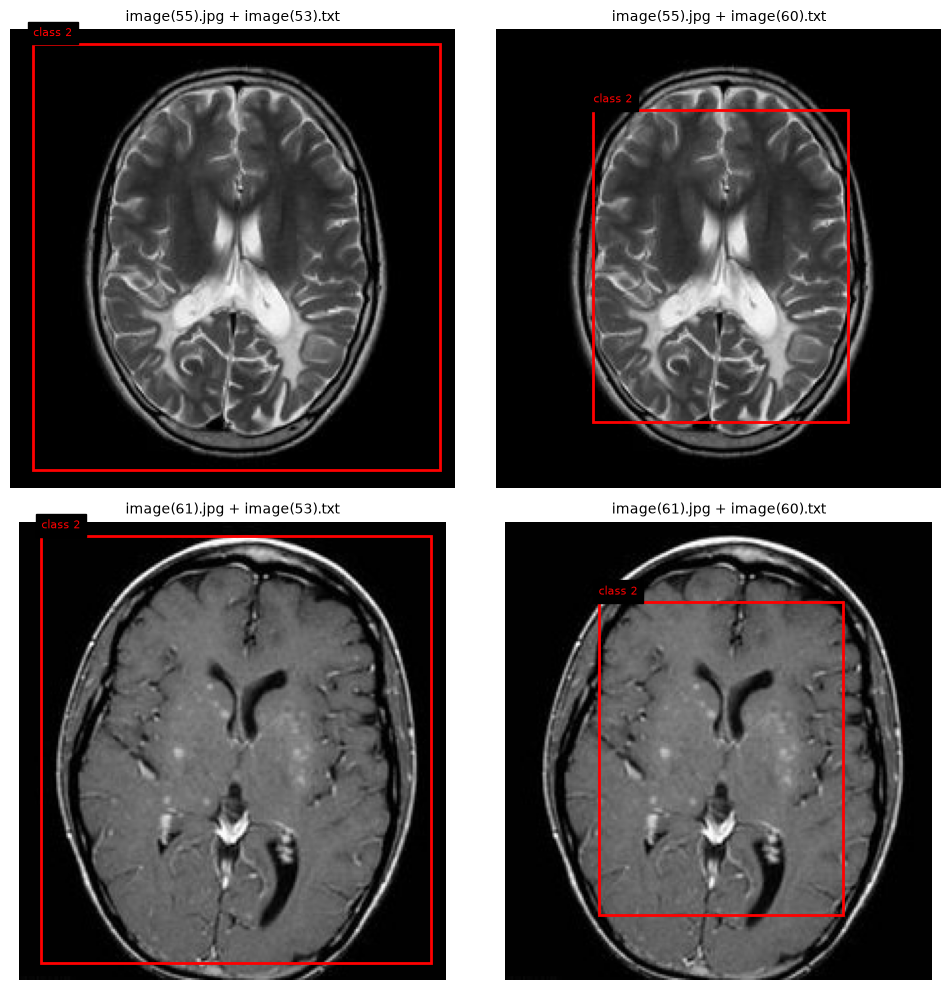

In [8]:
import matplotlib.pyplot as plt, matplotlib.patches as patches
from PIL import Image
from pathlib import Path

def load_labels(p):
    if not p.exists(): return []
    return [tuple(float(v) for v in ln.split()) for ln in p.read_text().splitlines() if ln.strip()]

def draw(ax, img_path, lbl_path, title, color="red"):
    img = Image.open(img_path).convert("RGB"); W, H = img.size
    ax.imshow(img); ax.axis("off"); ax.set_title(title, fontsize=10)
    for cid, xc, yc, w, h in load_labels(lbl_path):
        x0, y0 = (xc-w/2)*W, (yc-h/2)*H
        ax.add_patch(patches.Rectangle((x0,y0), w*W, h*H, lw=2, edgecolor=color, fill=False))
        ax.text(x0, y0-4, f"class {int(cid)}", color=color, fontsize=8, backgroundcolor="black")

# Paths to the ORIGINAL orphan labels and the CLEAN images
ORIG_VAL_LBL = Path(r"C:\Users\ycode\Desktop\2nd_YouCode\briefs\MRI_class_DL\data_set\Val\No Tumor\labels")
CLEAN_VAL_IMG = Path(r"C:\Users\ycode\Desktop\2nd_YouCode\briefs\MRI_class_DL\data_set_split\val\No Tumor\images")

fig, axes = plt.subplots(2, 2, figsize=(10, 10))

# Top-left: image(55) + image(53).txt
draw(axes[0,0], CLEAN_VAL_IMG/"image(55).jpg", ORIG_VAL_LBL/"image(53).txt", 
     "image(55).jpg + image(53).txt")

# Top-right: image(55) + image(60).txt
draw(axes[0,1], CLEAN_VAL_IMG/"image(55).jpg", ORIG_VAL_LBL/"image(60).txt", 
     "image(55).jpg + image(60).txt")

# Bottom-left: image(61) + image(53).txt
draw(axes[1,0], CLEAN_VAL_IMG/"image(61).jpg", ORIG_VAL_LBL/"image(53).txt", 
     "image(61).jpg + image(53).txt")

# Bottom-right: image(61) + image(60).txt
draw(axes[1,1], CLEAN_VAL_IMG/"image(61).jpg", ORIG_VAL_LBL/"image(60).txt", 
     "image(61).jpg + image(60).txt")

plt.tight_layout(); plt.show()

In [9]:
missing_images = ["image(53)", "image(60)"]
for stem in missing_images:
    hits = list(DATASET_ROOT.rglob(f"{stem}.jpg"))
    print(f"{stem}.jpg found in:", [str(h.relative_to(DATASET_ROOT)) for h in hits] or "NOWHERE")

image(53).jpg found in: NOWHERE
image(60).jpg found in: NOWHERE


## 1.4 — Label file contents

For every `.txt` label file, record: is it empty, how many boxes it has,
and which `class_id` values appear.

Key questions:
- Do "No Tumor" files uniformly contain `class_id 2` (whole-brain boxes)?
- Do Glioma / Meningioma / Pituitary files uniformly contain `0 / 1 / 3` respectively?
- Are there cross-contaminations (e.g. `class_id 0` inside No Tumor files)?

In [10]:
records = []
for s in SPLITS:
    for c in CLASSES:
        for f in (DATASET_ROOT / s / c / "labels").glob("*.txt"):
            lines = [ln for ln in f.read_text().splitlines() if ln.strip()]
            class_ids = []
            for ln in lines:
                parts = ln.split()
                if parts:
                    try:
                        class_ids.append(int(float(parts[0])))
                    except ValueError:
                        class_ids.append(-1)
            records.append({
                "split": s, "class": c, "file": f.name,
                "n_boxes": len(lines),
                "class_ids": tuple(sorted(set(class_ids))),
            })

lab = pd.DataFrame(records)

summary = (
    lab.assign(is_empty=lab["n_boxes"] == 0)
       .groupby(["split", "class"])
       .agg(
           files=("file", "count"),
           empty=("is_empty", "sum"),
           non_empty=("is_empty", lambda x: (~x).sum()),
           min_boxes=("n_boxes", "min"),
           max_boxes=("n_boxes", "max"),
           mean_boxes=("n_boxes", "mean"),
       )
)
display(summary.round(2))

print("\nDistinct class_id sets per (split, class):")
print(lab.groupby(["split", "class"])["class_ids"].value_counts().rename("count"))

files  empty  non_empty  min_boxes  max_boxes  mean_boxes
split class                                                                
Train Glioma       1153      0       1153          1          4        1.30
      Meningioma   1449      0       1449          1          5        1.09
      No Tumor      711      0        711          1          1        1.00
      Pituitary    1424      0       1424          1          3        1.07
Val   Glioma        136      1        135          0          4        1.21
      Meningioma    140      0        140          1          3        1.06
      No Tumor      100      0        100          1          1        1.00
      Pituitary     136      0        136          1          2        1.05


Distinct class_id sets per (split, class):
split  class       class_ids
Train  Glioma      (0,)         1000
                   (0, 3)        149
                   (1,)            2
                   (3,)            1
                   (0, 1)          1
       Meningioma  (1,)         1349
                   (1, 3)         89
                   (3,)            9
                   (0,)            2
       No Tumor    (2,)          711
       Pituitary   (3,)         1423
                   (1,)            1
Val    Glioma      (0,)          123
                   (0, 3)         12
                   ()              1
       Meningioma  (1,)          134
                   (1, 3)          6
       No Tumor    (2,)          100
       Pituitary   (3,)          136
Name: count, dtype: int64


## 1.7 — Visual spot-check

Two goals:
1. Confirm the No Tumor whole-brain-box convention across random samples.
2. Investigate cross-contamination: files where Glioma/Meningioma labels contain `class_id 3` (Pituitary) boxes.

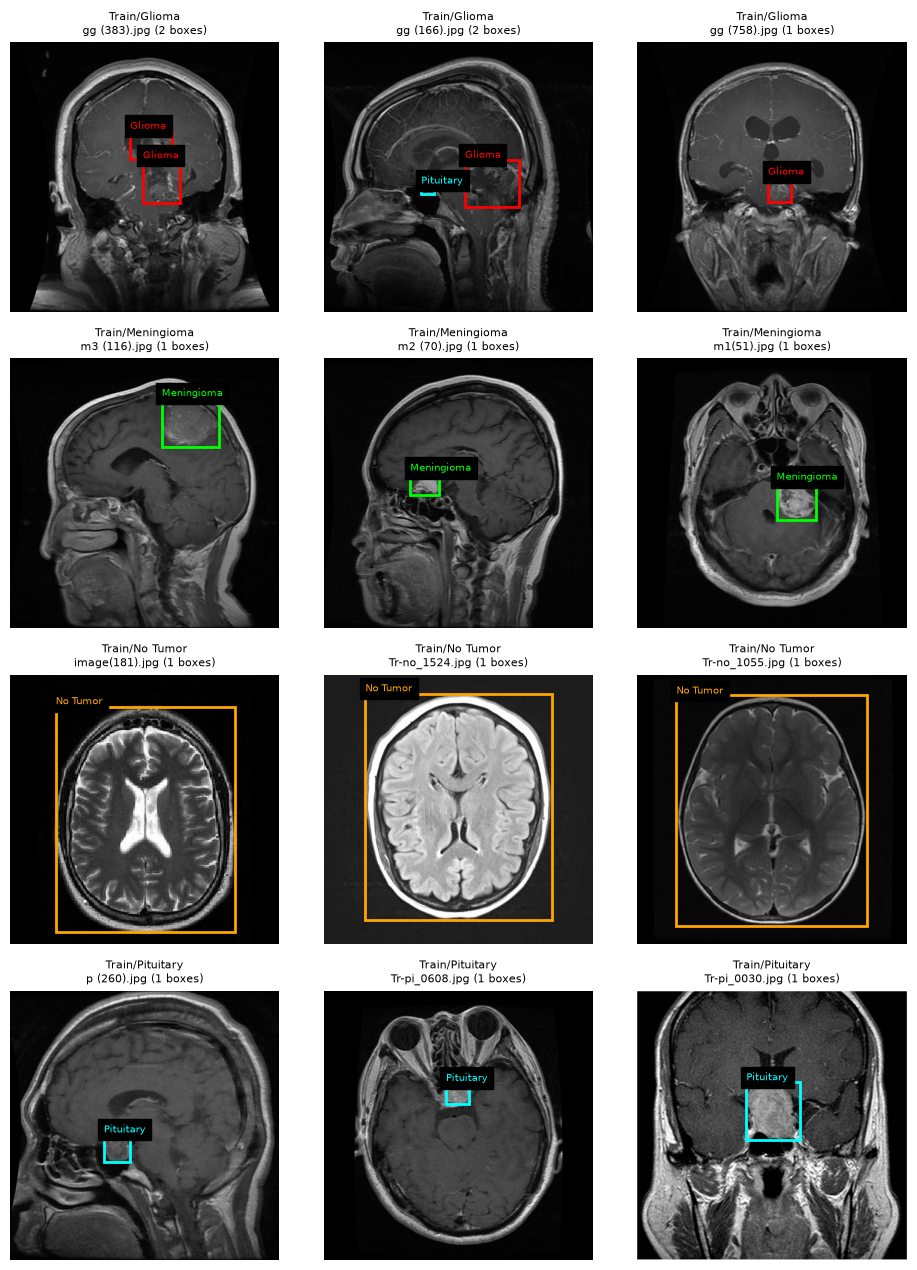

In [11]:
import random, matplotlib.pyplot as plt, matplotlib.patches as patches
from PIL import Image

N_PER_CLASS, SPLIT_TO_VIEW, SEED = 3, "Train", 42
random.seed(SEED)

ID_COLORS = {0: "red", 1: "lime", 2: "orange", 3: "cyan"}
ID_NAMES  = {0: "Glioma", 1: "Meningioma", 2: "No Tumor", 3: "Pituitary"}

def load_labels(p):
    if not p.exists(): return []
    out = []
    for ln in p.read_text().splitlines():
        x = ln.strip().split()
        if len(x) == 5:
            out.append(tuple(float(v) for v in x))
    return out

fig, axes = plt.subplots(len(CLASSES), N_PER_CLASS,
                         figsize=(N_PER_CLASS*3.2, len(CLASSES)*3.2))
for r, c in enumerate(CLASSES):
    base = DATASET_ROOT / SPLIT_TO_VIEW / c
    picks = random.sample(sorted((base/"images").glob("*.jpg")), N_PER_CLASS)
    for k, ip in enumerate(picks):
        ax = axes[r][k]
        img = Image.open(ip).convert("RGB"); W, H = img.size
        ax.imshow(img); ax.axis("off")
        lp = base/"labels"/f"{ip.stem}.txt"
        for cid, xc, yc, w, h in load_labels(lp):
            x0, y0 = (xc-w/2)*W, (yc-h/2)*H
            ax.add_patch(patches.Rectangle((x0,y0), w*W, h*H,
                          lw=2, edgecolor=ID_COLORS.get(int(cid),"white"), fill=False))
            ax.text(x0, y0-4, ID_NAMES.get(int(cid), f"id {int(cid)}"),
                    color=ID_COLORS.get(int(cid),"white"), fontsize=7, backgroundcolor="black")
        ax.set_title(f"{SPLIT_TO_VIEW}/{c}\n{ip.name} ({len(load_labels(lp))} boxes)", fontsize=8)
plt.tight_layout(); plt.show()

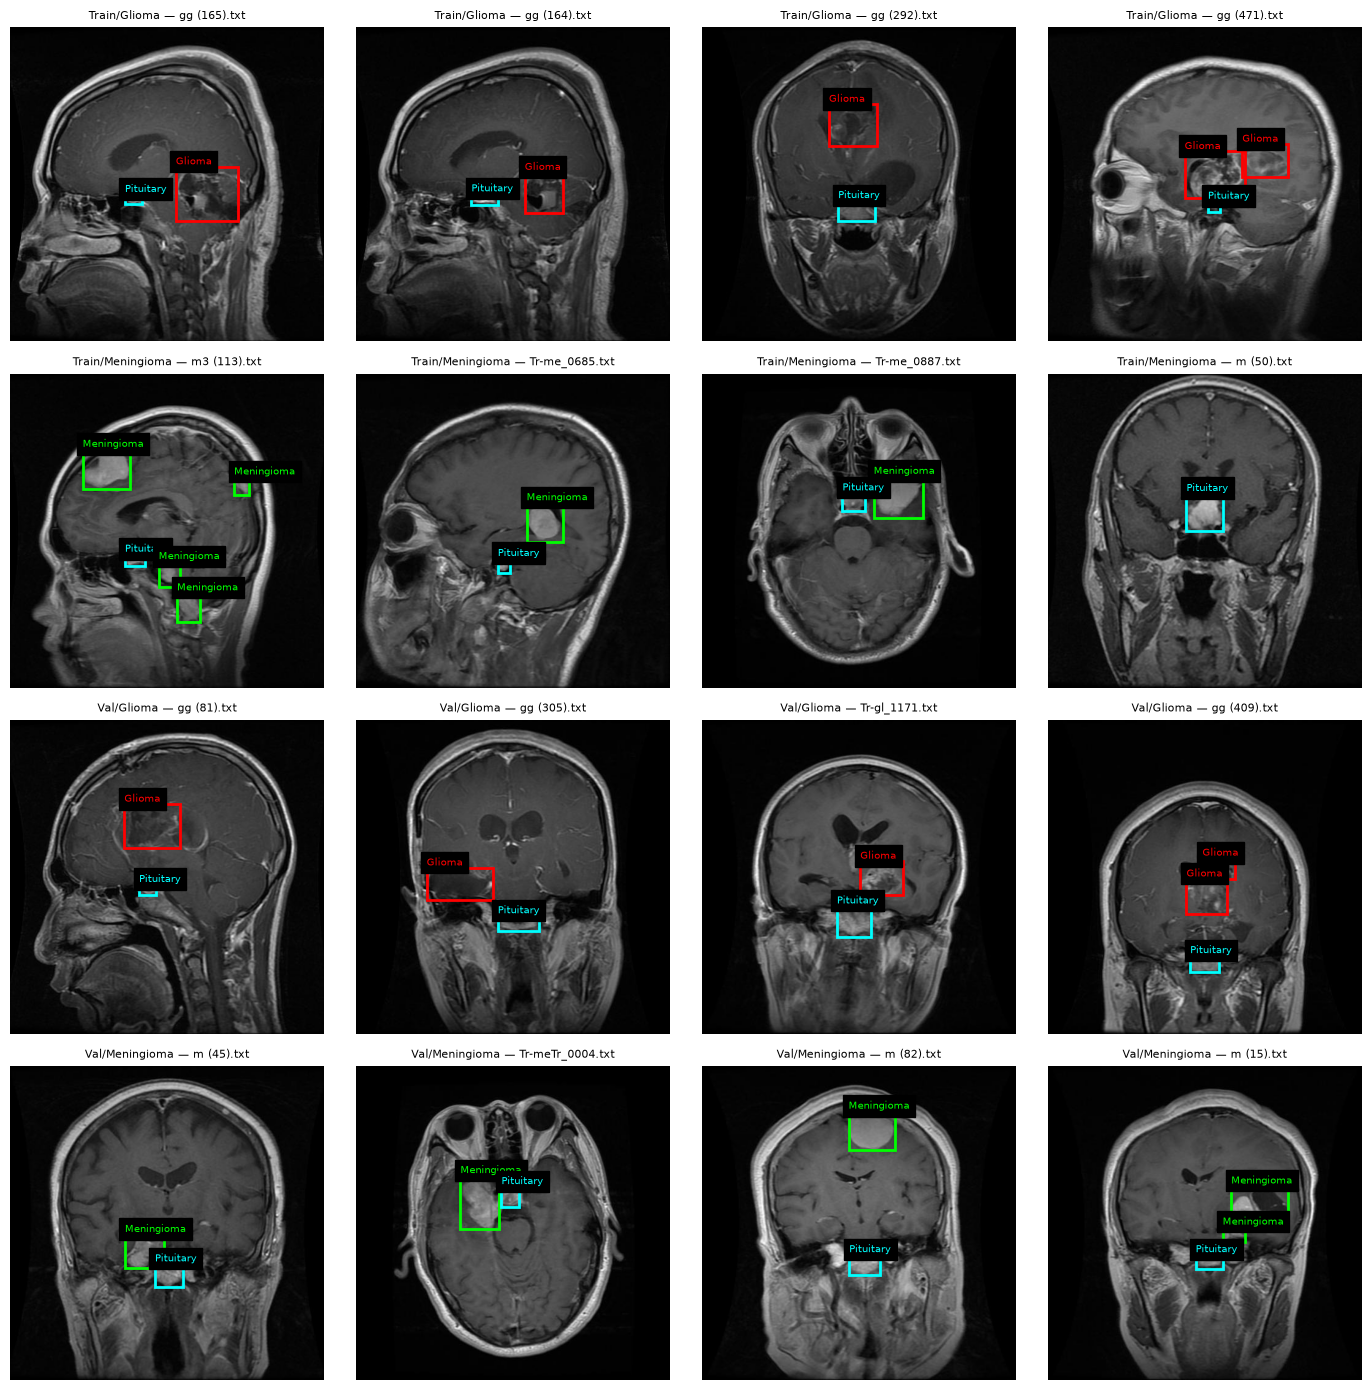

In [12]:
# Find files whose label content includes class 3 but folder is not Pituitary
SUSPECT_DIRS = [("Train","Glioma"), ("Train","Meningioma"),
                ("Val","Glioma"),   ("Val","Meningioma")]
N_SAMPLES = 4

fig, axes = plt.subplots(len(SUSPECT_DIRS), N_SAMPLES,
                         figsize=(N_SAMPLES*3.5, len(SUSPECT_DIRS)*3.5))
for r, (s, c) in enumerate(SUSPECT_DIRS):
    base = DATASET_ROOT / s / c
    hits = []
    for lp in (base/"labels").glob("*.txt"):
        ids = {int(float(ln.split()[0])) for ln in lp.read_text().splitlines() if ln.strip()}
        if 3 in ids:
            hits.append(lp)
    picks = random.sample(hits, min(N_SAMPLES, len(hits)))
    for k in range(N_SAMPLES):
        ax = axes[r][k]; ax.axis("off")
        if k >= len(picks):
            continue
        lp = picks[k]
        ip = base/"images"/f"{lp.stem}.jpg"
        img = Image.open(ip).convert("RGB"); W, H = img.size
        ax.imshow(img)
        for cid, xc, yc, w, h in load_labels(lp):
            x0, y0 = (xc-w/2)*W, (yc-h/2)*H
            ax.add_patch(patches.Rectangle((x0,y0), w*W, h*H,
                          lw=2, edgecolor=ID_COLORS.get(int(cid),"white"), fill=False))
            ax.text(x0, y0-4, ID_NAMES.get(int(cid), f"id {int(cid)}"),
                    color=ID_COLORS.get(int(cid),"white"), fontsize=7, backgroundcolor="black")
        ax.set_title(f"{s}/{c} — {lp.name}", fontsize=8)
plt.tight_layout(); plt.show()